<a href="https://colab.research.google.com/github/yeugeneu/IAT360-CV-13-Cloud-Type-Classifier/blob/Marielle-Test/Cloud_type_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preprocessing
We have to convert the dataset into that acceptable by YOLO.
- Heirarchy of folders should be the one accepted by YOLO
- Labels format should be object detection for YOLOv8
```
class x_center y_center width height
```

- Labels files should be .txt files with an object in the image per row

1. Make sure you download and extract the dataset [CloudDataset](https://app.roboflow.com/eugene-yu/cloud-qthye-mirzy/1) forked from [Roboflow Cloud Computer Vision Model dataset](https://universe.roboflow.com/ip2-kbjz5/cloud-qthye/browse?queryText=&pageSize=100&startingIndex=0&browseQuery=true)


2. Rename the folder to 'CloudDataset'

3. Below steps will guide you through converting the original dataset to the folder hierarchy we wish to use


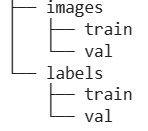

## Import required libraries

In [ ]:
import glob
import os
import random
import shutil
from PIL import Image
import cv2
import matplotlib.pyplot as plt
import pandas as pd

## Re-organize source Dataset images/labels

Load all images and labels located inside the "CloudDataset" folder

In [ ]:
# Set train, validate, and test dataset paths
train_dir_img = 'CloudDataset/train/images'
train_dir_lbl = 'CloudDataset/train/labels'

val_dir_img = 'CloudDataset/valid/images'
val_dir_lbl = 'CloudDataset/valid/labels'

In [ ]:
import os

# Define source directory paths directly
train_dir_img = 'CloudDataset/train/images'
train_dir_lbl = 'CloudDataset/train/labels'

val_dir_img = 'CloudDataset/valid/images'
val_dir_lbl = 'CloudDataset/valid/labels'

test_dir_img = 'CloudDataset/test/images'
test_dir_lbl = 'CloudDataset/test/labels'

# Define directories to clean
dirs_to_clean = [
    (train_dir_img, train_dir_lbl),
    (val_dir_img, val_dir_lbl)
]

seen_bases = set()

for img_dir, lbl_dir in dirs_to_clean:
    if not os.path.exists(img_dir):
        print(f"Directory does not exist, skipping: {img_dir}")
        continue

    files = sorted(os.listdir(img_dir))

    removed_count = 0
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            # Roboflow export formats usually contain '.rf.' before the unique hash
            # e.g., 'Ac-N001_jpg.rf.8c98886d88bb955b60652b2a5f2f42a6.jpg' -> base 'Ac-N001_jpg'
            if '.rf.' in file:
                base_name = file.split('.rf.')[0]
            else:
                base_name = os.path.splitext(file)[0]

            img_path = os.path.join(img_dir, file)

            # Match corresponding label txt file
            label_file = os.path.splitext(file)[0] + '.txt'
            lbl_path = os.path.join(lbl_dir, label_file)

            if base_name in seen_bases:
                # Duplicate found, remove both image and label
                if os.path.exists(img_path):
                    os.remove(img_path)
                if os.path.exists(lbl_path):
                    os.remove(lbl_path)
                removed_count += 1
            else:
                # First instance, keep it
                seen_bases.add(base_name)

    print(f"Cleaned {img_dir}: Kept {len(seen_bases)} unique images, removed {removed_count} augmented instances.")

Cleaned CloudDataset/train/images: Kept 2310 unique images, removed 1119 augmented instances.
Cleaned CloudDataset/valid/images: Kept 2521 unique images, removed 646 augmented instances.


Create new root folder called "All_data", with 2 child folders "images" and "labels"

In [ ]:
os.makedirs('All_data/images')
os.makedirs('All_data/labels')

Copy the label txt files and image jpg files to the new folders created

In [ ]:
#set the paths to labels and images directory for All data
label_dir= "All_data/labels"
image_dir= "All_data/images"

In [ ]:
# Source directories mapped to their target categories
image_sources = [train_dir_img, val_dir_img]
label_sources = [train_dir_lbl, val_dir_lbl]

# Copy and process all images to image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    base, ext = os.path.splitext(file)
                    # Replace '.' with '-' in the filename base
                    safe_base = base.replace(".", "-")
                    new_filename = safe_base + ".jpg"
                    image.save(os.path.join(image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                base, ext = os.path.splitext(file)
                # Replace '.' with '-' in the filename base
                safe_base = base.replace(".", "-")
                new_filename = safe_base + ext
                shutil.copy(os.path.join(src_dir, file), os.path.join(label_dir, new_filename))

Take a look at the first 4 images in the "Final_data/images" folder to make sure the images are moved correctly

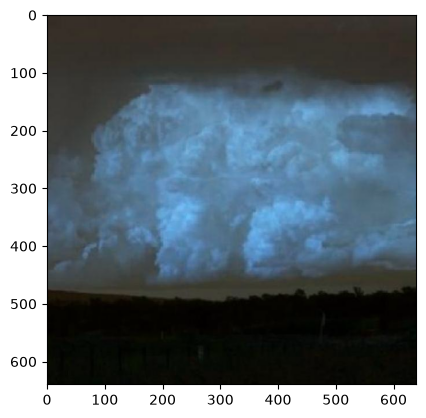

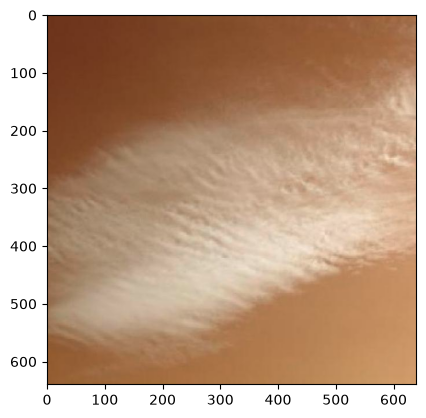

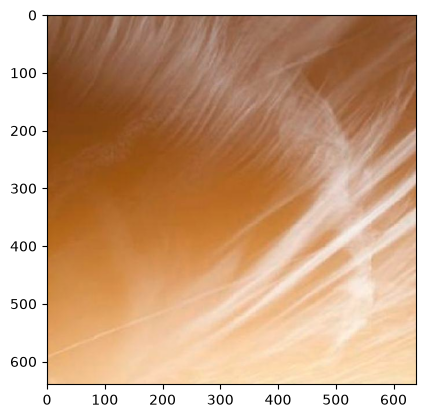

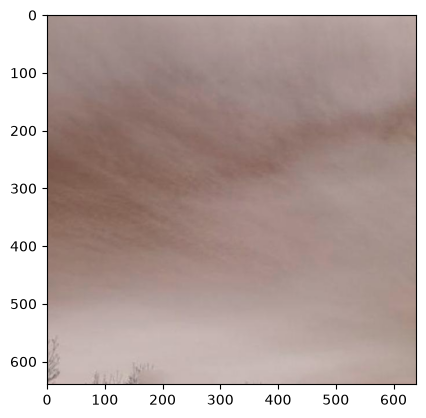

In [ ]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir))):
    img = cv2.imread(os.path.join(image_dir, image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

Check the Data balance

class_name
Stratocumulus    344
Cirrostratus     288
Nimbostratus     274
Cirrocumulus     260
Cumulonimbus     235
Altocumulus      219
Contrails        205
Stratus          204
Altostratus      188
Cumulus          178
Cirrus           140
Name: count, dtype: int64


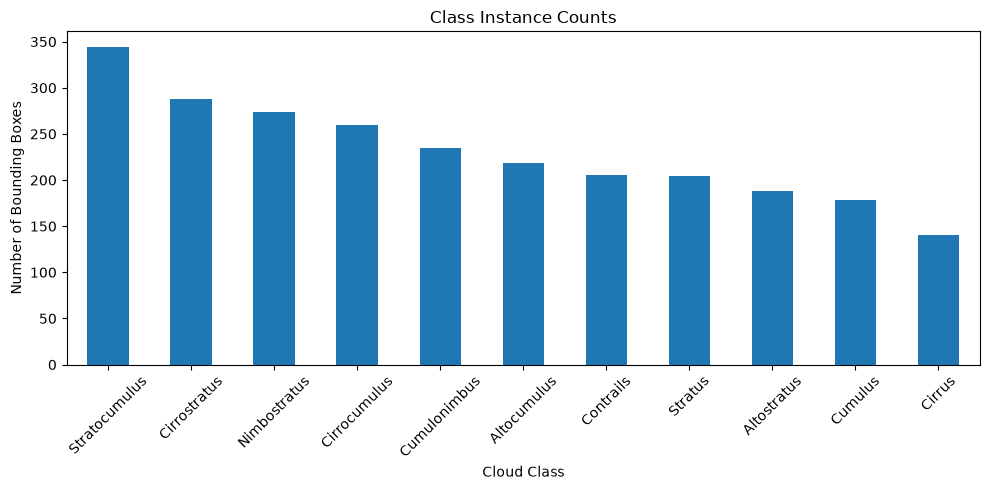

In [ ]:
# 1. Define your class mapping dictionary
class_map = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# 2. Gather label annotation files
labels_dir = "All_data/labels"
annotation_files = glob.glob(os.path.join(labels_dir, "*.txt"))

records = []
for file in annotation_files:
    with open(file, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                records.append(int(parts[0]))

# Create DataFrame
df = pd.DataFrame(records, columns=['class_id'])

# Map class IDs to names
df['class_name'] = df['class_id'].map(class_map)

# Value counts table
print(df['class_name'].value_counts())

# Plot distribution
df['class_name'].value_counts().plot(kind='bar', figsize=(10, 5), title="Class Instance Counts")
plt.xlabel("Cloud Class")
plt.ylabel("Number of Bounding Boxes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Split the source data
Split into 80-20 train-validation sets and re-organize the data into correct sub-folders

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Load the sorted lists of all images and matching labels
# Sorting ensures that images and labels pair up correctly (e.g., image[i] matches label[i])
images_dir = "All_data/images"
labels_dir = "All_data/labels"

# Get all file names and sort them alphabetically
image_files = sorted(os.listdir(images_dir))
label_files = sorted(os.listdir(labels_dir))

# Double check we are matching base names (e.g., image_01.jpg maps to image_01.txt)
# We'll filter to make sure we only split perfectly matching image-label pairs
valid_images = []
valid_labels = []

for img in image_files:
    base_name = os.path.splitext(img)[0]
    label_name = f"{base_name}.txt"
    if label_name in label_files:
        valid_images.append(os.path.join(images_dir, img))
        valid_labels.append(os.path.join(labels_dir, label_name))

# 2. Split into 80% train+validation and 20% test set
X_train, X_validation, y_train, y_validation = train_test_split(
    valid_images,
    valid_labels,
    test_size=0.20,
    random_state=42
)

print(f"Split completed:")
print(f"  - Train set size: {len(X_train)} pairs")
print(f"  - Validation set size: {len(X_validation)} pairs")


Split completed:
  - Train set size: 2016 pairs
  - Validation set size: 505 pairs


In [ ]:
# Define the target subdirectories
splits = ['train', 'val']
for split in splits:
    os.makedirs(os.path.join("All_data/images", split), exist_ok=True)
    os.makedirs(os.path.join("All_data/labels", split), exist_ok=True)

# Helper function to move a list of files to their respective folder
def move_files(file_paths, destination_folder):
    for path in file_paths:
        if os.path.exists(path):
            filename = os.path.basename(path)
            shutil.move(path, os.path.join(destination_folder, filename))

# Move image sets
move_files(X_train, "All_data/images/train")
move_files(X_validation, "All_data/images/val")

# Move label sets
move_files(y_train, "All_data/labels/train")
move_files(y_validation, "All_data/labels/val")

# Verify counts in new structured folders
print("\nPhysical Split Verification:")
for split in splits:
    img_count = len(os.listdir(os.path.join("All_data/images", split)))
    lbl_count = len(os.listdir(os.path.join("All_data/labels", split)))
    print(f"  - {split.capitalize()} Set: {img_count} images | {lbl_count} labels")



Physical Split Verification:
  - Train Set: 2016 images | 2016 labels
  - Val Set: 505 images | 505 labels


## Organize group member images and Move them into test folder as test set

Download the images collected from all 4 group members ([FirstName]_Cloud_Data_Labeled) located in this link https://1sfu-my.sharepoint.com/:f:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013?d=w11d6cbb929af48b29ee060bcf9c1bf78&csf=1&web=1&e=WJnLSs


In [ ]:
# creates Members_Dataset and moves every folder ending in _CloudData_Labeled
import os, shutil

os.makedirs("Members_Dataset", exist_ok=True)

for name in os.listdir("."):
    if name.endswith("_CloudData_Labeled") and os.path.isdir(name):
        shutil.move(name, os.path.join("Members_Dataset", name))
        print("moved", name)

# show what's inside so you can check the structure
for name in os.listdir("Members_Dataset"):
    print(name, "->", os.listdir(os.path.join("Members_Dataset", name)))

Dalena_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']
Marielle_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']
Eugene_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']
Martina_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']


In [ ]:
# Set all paths to the dataset
eugene_dir_img = 'Members_Dataset/Eugene_CloudData_Labeled/images'
eugene_dir_lbl = 'Members_Dataset/Eugene_CloudData_Labeled/labels'

dalena_dir_img = 'Members_Dataset/Dalena_CloudData_Labeled/images'
dalena_dir_lbl = 'Members_Dataset/Dalena_CloudData_Labeled/labels'

martina_dir_img = 'Members_Dataset/Martina_CloudData_Labeled/images'
martina_dir_lbl = 'Members_Dataset/Martina_CloudData_Labeled/labels'

marielle_dir_img = 'Members_Dataset/Marielle_CloudData_Labeled/images'
marielle_dir_lbl = 'Members_Dataset/Marielle_CloudData_Labeled/labels'

Copy the label txt files and image jpg files to the new folders created

In [ ]:
#set the paths to labels and images directory for test data
test_label_dir= "All_data/labels/test"
test_image_dir= "All_data/images/test"

os.makedirs(os.path.join("All_data/labels/test"), exist_ok=True)
os.makedirs(os.path.join("All_data/images/test"), exist_ok=True)

Every image from every member gets converted to RGB .jpg and saved into All_data/images/test. Every label .txt from every member gets copied into All_data/labels/test

In [ ]:
# Source directories mapped to their target categories
image_sources = [eugene_dir_img, dalena_dir_img, martina_dir_img, marielle_dir_img]
label_sources = [eugene_dir_lbl, dalena_dir_lbl, martina_dir_lbl, marielle_dir_lbl]

# Copy and process all images to test_image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    new_filename = os.path.splitext(file)[0] + ".jpg"
                    image.save(os.path.join(test_image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to test_label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                shutil.copy(os.path.join(src_dir, file), os.path.join(test_label_dir, file))

## Check for missing files

Each set should contain the same amount of images and labels

In [ ]:
train_img = "All_data/images/train"
train_lbl = "All_data/labels/train"
val_img = "All_data/images/val"
val_lbl = "All_data/labels/val"
test_img = "All_data/images/test"
test_lbl = "All_data/labels/test"

# Group the folder pairs together for verification
pairs = [
    ("Train Set", train_img, train_lbl),
    ("Validation Set", val_img, val_lbl),
    ("Test Set", test_img, test_lbl)
]

for name, img_folder, lbl_folder in pairs:
    num_images = len([f for f in os.listdir(img_folder) if os.path.isfile(os.path.join(img_folder, f))])
    num_labels = len([f for f in os.listdir(lbl_folder) if os.path.isfile(os.path.join(lbl_folder, f))])
    print(f"{name}: {num_images} images | {num_labels} labels")
    assert num_images == num_labels, f"Mismatch in {name}! Images: {num_images}, Labels: {num_labels}"

Train Set: 2016 images | 2016 labels
Validation Set: 505 images | 505 labels
Test Set: 120 images | 120 labels


Randomly pick an image and a label from each set to check if annotation can be populated

Visualizing from train set: Ac-N130_jpg-rf-0210ab888ac4303e89495a3d99262bde.jpg


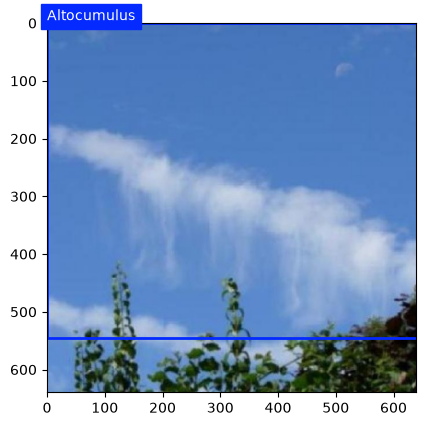

Visualizing from val set: Ct-N196_jpg-rf-1e61c589c9ed603081a9f328540caee7.jpg


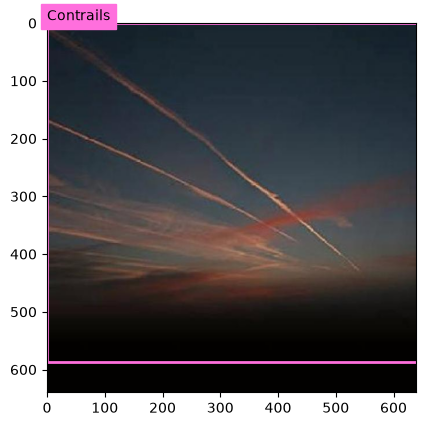

Visualizing from test set: e9dd9ad0-own_marielle_02.jpg


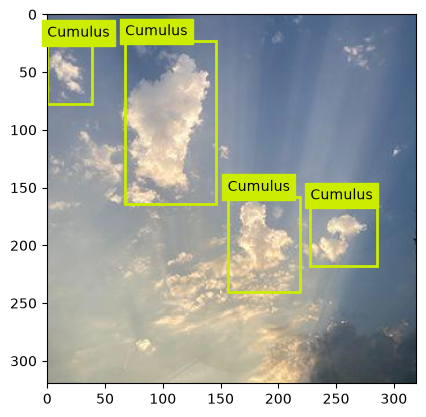

In [ ]:
from ultralytics.data.utils import visualize_image_annotations
# define the class map
class_map = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# Splits to choose from
splits = ["train", "val", "test"]

for split in splits:
    img_dir = f"All_data/images/{split}"
    lbl_dir = f"All_data/labels/{split}"

    if os.path.exists(img_dir) and os.path.exists(lbl_dir):
        # Get a list of all image files in this split
        image_files = [f for f in os.listdir(img_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]

        if image_files:
            # Pick 1 random image from this split
            random_image = random.choice(image_files)

            # Construct matching image and label paths
            base_name = os.path.splitext(random_image)[0]
            random_image_path = os.path.join(img_dir, random_image)
            random_label_path = os.path.join(lbl_dir, f"{base_name}.txt")

            # Visualize
            print(f"Visualizing from {split} set: {random_image}")
            visualize_image_annotations(
                random_image_path,
                random_label_path,
                class_map,
            )
        else:
            print(f"No images found in {img_dir}")
    else:
        print(f"Directory does not exist for split: {split}")

# Model Training

In [4]:
%pip install ultralytics
import ultralytics

ultralytics.checks()

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [5]:
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# import zipfile
# import os

# zip_path = "/content/drive/MyDrive/IAT 360/All_data.zip"
# extract_path = "/content/drive/MyDrive/IAT 360/"

# with zipfile.ZipFile(zip_path, 'r') as zip_ref:
#     zip_ref.extractall(extract_path)

# print("Extraction complete!")

In [14]:
%cd "/content/drive/MyDrive/IAT 360"
%pwd
%ls

/content/drive/MyDrive/IAT 360
All_data/  runs/


In [15]:
%%writefile config.yaml
path: All_data
train: images/train
val: images/val
test: images/test

# Classes
nc: 11 # replace based on your dataset's number of classes

# Class names
names:
    0: Altocumulus
    1: Altostratus
    2: Cirrocumulus
    3: Cirrostratus
    4: Cirrus
    5: Contrails
    6: Cumulonimbus
    7: Cumulus
    8: Nimbostratus
    9: Stratocumulus
    10: Stratus


Writing config.yaml


In [16]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')

In [18]:
# Train using config.yaml and store results inside your Google Drive directory
model.train(
    data="config.yaml",
    epochs=50,                                                    # 50 epochs is a good baseline length
    patience=10,                                                  # Increased from 5 to 10 to avoid premature early stopping
    batch=16,                                                     # Standard batch size for 16GB GPU VRAM
    device=0,                                                     # Force training on the GPU (Tesla T4)
    project="/content/drive/MyDrive/IAT 360/runs",                 # Keep runs organized inside your Drive
    name="cloud_baseline_result_yolov8s"                         # Specific subfolder for this run
)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cloud_baseline_result_yolov8s-3, nbs=64, nms=None, opset=None, optimize=False

KeyboardInterrupt: 

In [19]:
!find /root /content -name "*.pt"

^C


## Hyperparameter Evaluation


Make sure you download both of the following files and unzip it to your google drive
* [All_data](https://1sfu-my.sharepoint.com/:u:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013/All_data.zip?d=w99f0d6e24789462aa37f4e1b3fae6704&csf=1&web=1&e=5w1wHF)
* [runs](https://1sfu-my.sharepoint.com/:u:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013/runs-20261106T030510Z-1-001.zip?d=w74339fa9a015476e8e23f2bc48ba9367&csf=1&web=1&e=ZKJmJJ)

Connect to your Google Drive to load the project files

In [18]:
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Set your current path to inside the Project folder containing the following:
* The baseline weight located inside `runs/cloud_baseline_result_yolov8s/weights/best.pt` path
* The `All_data` dataset folder
* The config.yaml file (if you don't have this created on your Google Drive, create it using the %%writefile config.yaml
 cell above under the Model Training section)

In [25]:
%cd "/content/drive/MyDrive/IAT 360"
import os

# Files to verify
files_to_check = [
    'runs/cloud_baseline_result_yolov8s/weights/best.pt',
    'config.yaml',
    'All_data',
    'All_data/images',
    'All_data/labels'
]

print("=== File Verification Results ===")
for path in files_to_check:
    exists = os.path.exists(path)
    status = "✅ FOUND" if exists else "❌ MISSING"
    print(f"{path:<50} : {status}")

/content/drive/MyDrive/IAT 360
=== File Verification Results ===
runs/cloud_baseline_result_yolov8s/weights/best.pt : ✅ FOUND
config.yaml                                        : ✅ FOUND
All_data                                           : ✅ FOUND
All_data/images                                    : ✅ FOUND
All_data/labels                                    : ✅ FOUND


Already done: coarse_wd_0.0005
Already done: coarse_wd_0.0
Already done: coarse_wd_0.005
Already done: coarse_wd_0.05


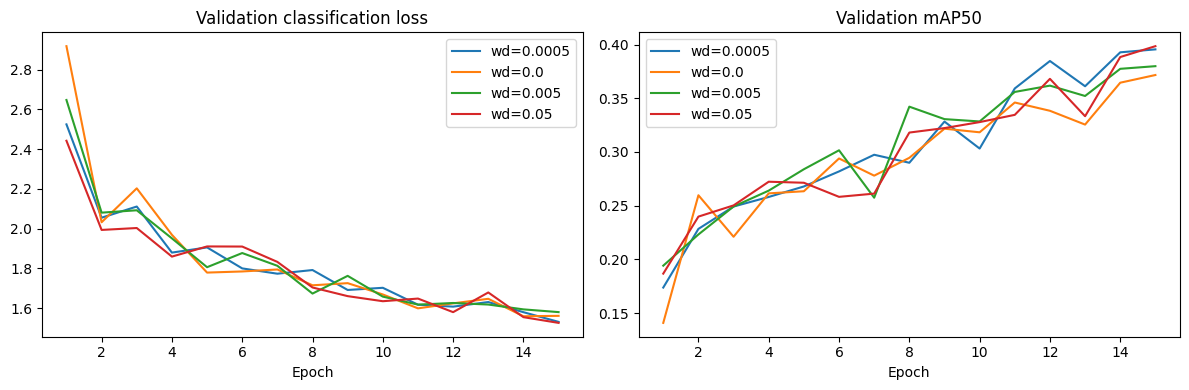

,weight_decay,best epoch,precision,recall,F1,mAP50,mAP50-95
3,0.0500,15,0.329,0.548,0.411,0.399,0.340
0,0.0005,15,0.296,0.582,0.392,0.396,0.348
2,0.0050,15,0.330,0.501,0.398,0.380,0.321
1,0.0000,15,0.315,0.503,0.387,0.372,0.322


Winner: 0.05
Already done: final_wd_0.05
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 9.7±3.2 MB/s, size: 11.1 KB)
val: Scanning /content/drive/MyDrive/IAT 360/All_data/labels/val.cache... 485 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 485/485 33.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 3.8it/s 8.2s
                   all        485        488       0.47      0.479      0.485      0.413
Speed: 1.4ms preprocess, 10.6ms inference, 0.0ms loss, 1.7ms postprocess per image
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.4 ms, read: 9.0±6.2 MB/s, size: 15.4 KB)
val: Scanning /co

,model,split,precision,recall,F1,mAP50,mAP50-95
0,baseline (wd 0.0005),val,0.470,0.479,0.474,0.485,0.413
1,baseline (wd 0.0005),test,0.359,0.185,0.244,0.111,0.056
2,best (wd 0.05),val,0.329,0.566,0.416,0.418,0.361
3,best (wd 0.05),test,0.129,0.229,0.165,0.106,0.063


In [26]:
import os, torch
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Always run from the project folder (fixes the "config.yaml not found" problem)
os.chdir("/content/drive/MyDrive/IAT 360")
assert torch.cuda.is_available(), "No GPU - switch runtime to T4 GPU first"
assert os.path.exists("config.yaml") and os.path.exists("All_data/images/val"), "Wrong folder or Drive not mounted"

RUNS = "/content/drive/MyDrive/IAT 360/runs"
BASELINE = f"{RUNS}/cloud_baseline_result_yolov8s"     # official 50-epoch baseline
WDS = [0.0005, 0.0, 0.005, 0.05]                       # baseline default first, then 3 test values

# Same settings as the baseline's auto choice; ONLY weight_decay changes
COMMON = dict(data="config.yaml", patience=10, batch=16, device=0,
              optimizer="AdamW", momentum=0.9, lr0=0.000667,
              cache=True, plots=False, project=RUNS, exist_ok=True)

def n_epochs(name):
    f = f"{RUNS}/{name}/results.csv"
    return len(pd.read_csv(f)) if os.path.exists(f) else 0

def train(wd, epochs, name, must_finish=True):
    done = os.path.exists(f"{RUNS}/{name}/weights/best.pt")
    if must_finish and done and n_epochs(name) < epochs:      # cut-off run: redo it
        print(f"{name}: only {n_epochs(name)}/{epochs} epochs found, retraining")
        done = False
    if done:
        print("Already done:", name); return
    YOLO("yolov8s.pt").train(epochs=epochs, weight_decay=wd, name=name, **COMMON)

# Step 1: four short runs, 15 epochs each (skips finished ones)
for WD in WDS:
    train(WD, 15, f"coarse_wd_{WD}")

# Step 2: compare the short runs and pick the winner
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for WD in WDS:
    df = pd.read_csv(f"{RUNS}/coarse_wd_{WD}/results.csv")
    df.columns = df.columns.str.strip()
    best = df.loc[df["metrics/mAP50(B)"].idxmax()]
    p, r = best["metrics/precision(B)"], best["metrics/recall(B)"]
    rows.append({"weight_decay": WD, "best epoch": int(best["epoch"]),
                 "precision": round(p, 3), "recall": round(r, 3),
                 "F1": round(2*p*r/(p+r+1e-9), 3),
                 "mAP50": round(best["metrics/mAP50(B)"], 3),
                 "mAP50-95": round(best["metrics/mAP50-95(B)"], 3)})
    axes[0].plot(df["epoch"], df["val/cls_loss"], label=f"wd={WD}")
    axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], label=f"wd={WD}")
axes[0].set_title("Validation classification loss")
axes[1].set_title("Validation mAP50")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

coarse = pd.DataFrame(rows).sort_values("mAP50", ascending=False)
display(coarse)
BEST_WD = float(coarse.iloc[0]["weight_decay"])
print("Winner:", BEST_WD)

# Step 3: train the winner for 50 epochs (skipped if the winner is the baseline default 0.0005)
# must_finish=False: early stopping can legitimately end this run before epoch 50
if BEST_WD != 0.0005:
    train(BEST_WD, 50, f"final_wd_{BEST_WD}", must_finish=False)

# Step 4: final comparison with the official baseline (validation + test)
final = {"baseline (wd 0.0005)": BASELINE}
if BEST_WD != 0.0005:
    final[f"best (wd {BEST_WD})"] = f"{RUNS}/final_wd_{BEST_WD}"

rows = []
for label, folder in final.items():
    m = YOLO(f"{folder}/weights/best.pt")
    for split in ["val", "test"]:
        r = m.val(data="config.yaml", split=split, project=RUNS, plots=False,
                  name=f"eval_{label.split()[0]}_{split}", exist_ok=True, verbose=False)
        p, rc = r.box.mp, r.box.mr
        rows.append({"model": label, "split": split,
                     "precision": round(p, 3), "recall": round(rc, 3),
                     "F1": round(2*p*rc/(p+rc+1e-9), 3),
                     "mAP50": round(r.box.map50, 3),
                     "mAP50-95": round(r.box.map, 3)})
pd.DataFrame(rows)

In [27]:
import os, pandas as pd
os.chdir("/content/drive/MyDrive/IAT 360")
RUNS = "/content/drive/MyDrive/IAT 360/runs"

rows = []
for wd in [0.0005, 0.0, 0.005, 0.05]:
    d = pd.read_csv(f"{RUNS}/coarse_wd_{wd}/results.csv"); d.columns = d.columns.str.strip()
    b = d.loc[d["metrics/mAP50(B)"].idxmax()]
    rows.append({"weight_decay": wd, "best epoch": int(b["epoch"]),
                 "precision": round(b["metrics/precision(B)"], 3), "recall": round(b["metrics/recall(B)"], 3),
                 "mAP50": round(b["metrics/mAP50(B)"], 3), "mAP50-95": round(b["metrics/mAP50-95(B)"], 3)})
print(pd.DataFrame(rows).sort_values("mAP50", ascending=False).to_string(index=False))

 weight_decay  best epoch  precision  recall  mAP50  mAP50-95
       0.0500          15      0.329   0.548  0.399     0.340
       0.0005          15      0.296   0.582  0.396     0.348
       0.0050          15      0.330   0.501  0.380     0.321
       0.0000          15      0.315   0.503  0.372     0.322


In [23]:
import pandas as pd
RUNS = "/content/drive/MyDrive/IAT 360/runs"
d = pd.read_csv(f"{RUNS}/final_wd_0.05/results.csv")
d.columns = d.columns.str.strip()
best_ep = int(d.loc[d["metrics/mAP50(B)"].idxmax(), "epoch"])
print("epochs run:", len(d), "| best epoch:", best_ep)

epochs run: 37 | best epoch: 35


In [15]:
import pandas as pd, shutil
RUNS = "/content/drive/MyDrive/IAT 360/runs"
for wd in [0.0005, 0.0, 0.005, 0.05]:
    f = f"{RUNS}/coarse_wd_{wd}/results.csv"
    n = len(pd.read_csv(f)) if os.path.exists(f) else 0
    print(wd, "epochs completed:", n)
    if 0 < n < 15:
        shutil.rmtree(f"{RUNS}/coarse_wd_{wd}")
        print("   deleted incomplete run, will be redone")

0.0005 epochs completed: 15
0.0 epochs completed: 15
0.005 epochs completed: 15
0.05 epochs completed: 15


## Evaluation metrics


In [9]:
from ultralytics import YOLO

# Load the baseline best weights directly
best_model_path = 'runs/cloud_baseline_result_yolov8s/weights/best.pt'
best = YOLO(best_model_path)
metrics = best.val(data="config.yaml")

print("mAP50-95:", metrics.box.map)
print("mAP50:", metrics.box.map50)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

for name, m in zip(best.names.values(), metrics.box.maps):
    print(name, round(m, 3))

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.2 ms, read: 9.9±2.1 MB/s, size: 11.0 KB)
val: Scanning /content/drive/MyDrive/IAT 360/All_data/labels/val.cache... 485 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 485/485 113.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 3.5it/s 8.8s
                   all        485        488       0.47      0.479      0.485      0.413
           Altocumulus         38         38      0.324      0.342      0.302      0.221
           Altostratus         40         40      0.312        0.4      0.404      0.363
          Cirrocumulus         55         55      0.547      0.691      0.664      0.635
          Cirrostratus         51         51      0.466      0.257      0.351      0.269
                Cirrus       

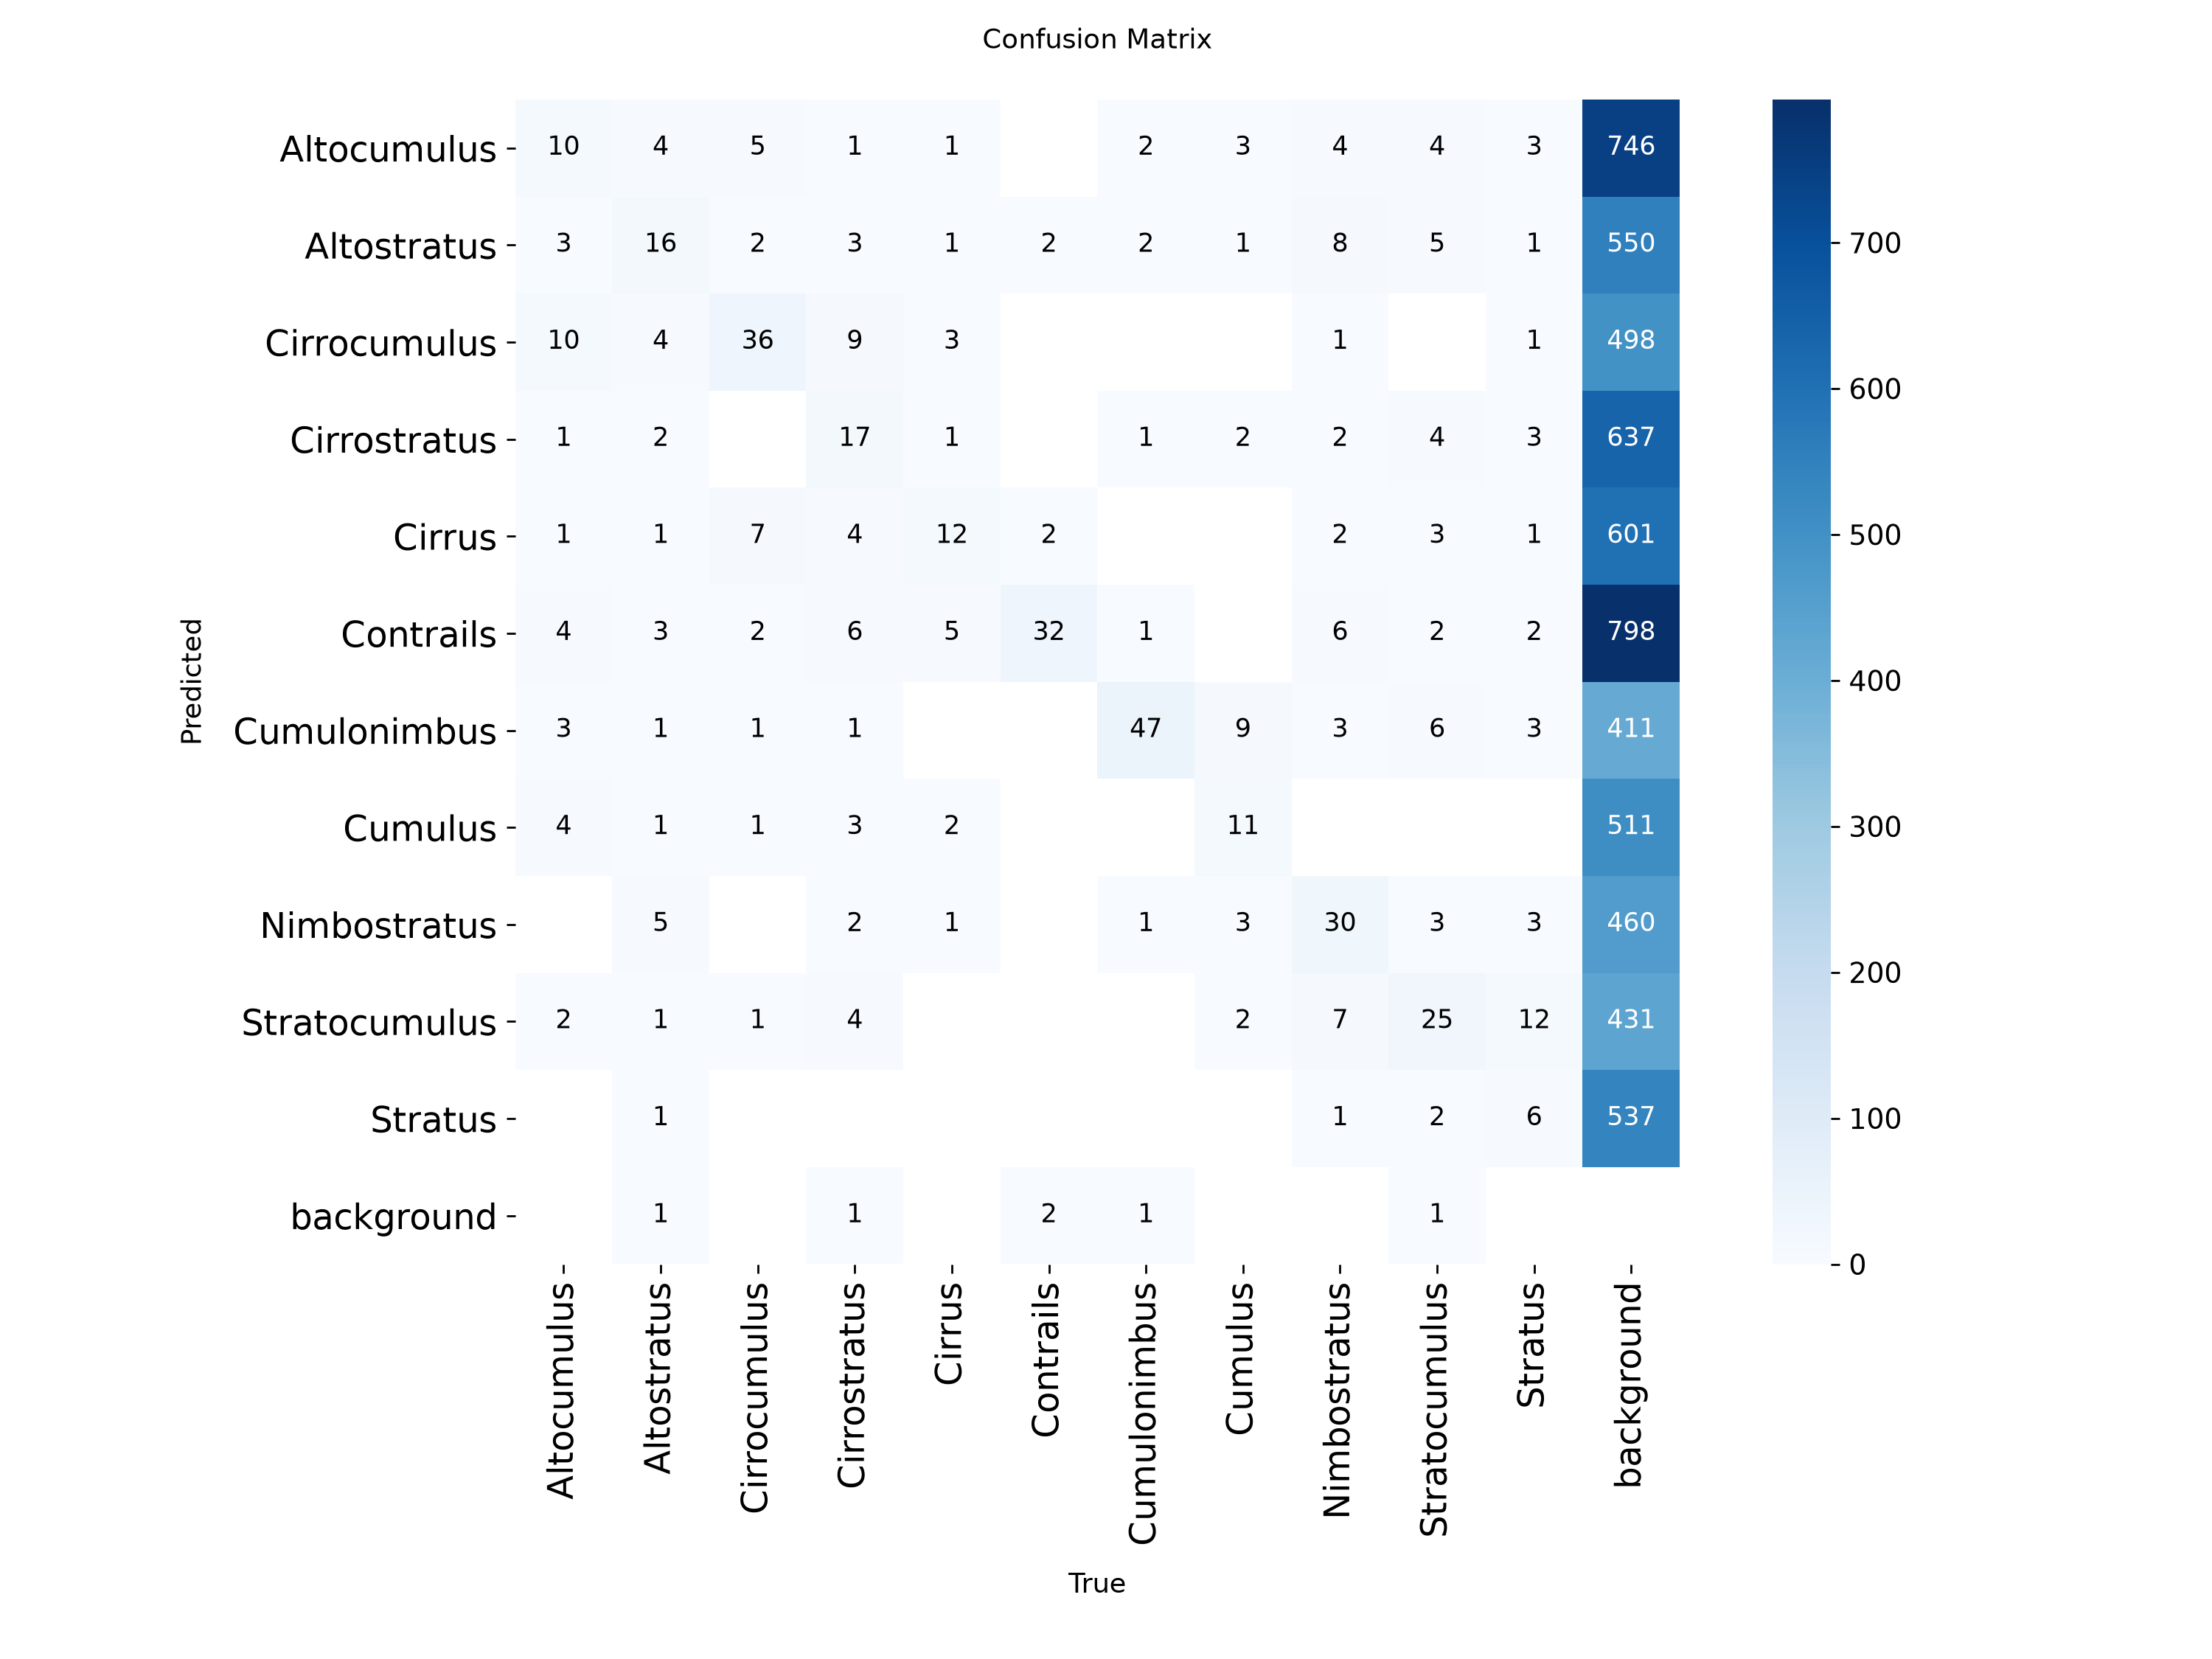

In [10]:
%matplotlib inline
from PIL import Image

Image.open('runs/detect/val/confusion_matrix.png')

# Model Evaluation